In [ ]:
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
chapters = { 1: ('Mr. Sherlock Holmes', ['Sherlock Holmes', 'Dr. Watson', 'Dr. James Mortimer']),
2: ('The Curse of the Baskervilles', ['Sherlock Holmes', 'Dr. Watson', 'Dr. James Mortimer', 'Sir Charles Baskerville']),
3: ('The Problem', ['Sherlock Holmes', 'Dr. Watson', 'Dr. James Mortimer', 'Sir Henry Baskerville']),
4: ('Sir Henry Baskerville', ['Sherlock Holmes', 'Dr. Watson', 'Dr. James Mortimer', 'Sir Henry Baskerville']),
5: ('Three Broken Threads', ['Sherlock Holmes', 'Dr. Watson', 'Dr. James Mortimer', 'Sir Henry Baskerville', 'Barrymore']),
6: ('Baskerville Hall', ['Dr. Watson', 'Dr. James Mortimer', 'Sir Henry Baskerville', 'Barrymore', 'Mrs. Barrymore', 'Perkins']),
7: ('The Stapletons of Merripit House', ['Dr. Watson', 'Sir Henry Baskerville', 'Jack Stapleton', 'Beryl Stapleton']),
8: ('First Report of Dr. Watson', ['Dr. Watson', 'Sir Henry Baskerville', 'Jack Stapleton', 'Beryl Stapleton', 'Barrymore', 'Frankland']),
9: ('Second Report of Dr. Watson', ['Dr. Watson', 'Sir Henry Baskerville', 'Jack Stapleton', 'Beryl Stapleton', 'Barrymore', 'Mrs. Barrymore', 'Selden']),
10: ('Extract from the Diary of Dr. Watson', ['Dr. Watson', 'Sir Henry Baskerville', 'Barrymore', 'Mrs. Barrymore', 'Selden', 'Laura Lyons']),
11: ('The Man on the Tor', ['Dr. Watson', 'Laura Lyons', 'Frankland', 'Sherlock Holmes', 'Selden']),
12: ('Death on the Moor', ['Sherlock Holmes', 'Dr. Watson', 'Selden', 'Jack Stapleton', 'Sir Henry Baskerville']),
13: ('Fixing the Nets', ['Sherlock Holmes', 'Dr. Watson', 'Sir Henry Baskerville', 'Barrymore', 'Mrs. Barrymore', 'Laura Lyons', 'Inspector Lestrade']),
14: ('The Hound of the Baskervilles', ['Sherlock Holmes', 'Dr. Watson', 'Inspector Lestrade', 'Sir Henry Baskerville', 'Jack Stapleton', 'Beryl Stapleton']),
15: ('A Retrospection', ['Sherlock Holmes', 'Dr. Watson', 'Dr. James Mortimer', 'Jack Stapleton', 'Beryl Stapleton', 'Laura Lyons'])
}

In [ ]:
G1 = nx.Graph()
for ch, (title, chars) in chapters.items():
  n = len(chars)
  newman = 1 / (n - 1) if n > 1 else 1
  for i in range(n):
    for j in range(i + 1, n):
      u, v = chars[i], chars[j]
      if G1.has_edge(u, v):
        G1[u][v]['weight'] += 1
        G1[u][v]['newman_weight'] += newman
      else:
        G1.add_edge(u, v, weight = 1, newman_weight = newman)

In [ ]:
G2 = nx.Graph()
for u, v, d in G1.edges(data = True):
  if d['newman_weight'] >= 0.45:
        G2.add_edge(u, v, weight = d['weight'], newman_weight = round(d['newman_weight'], 3))

In [ ]:
G3 = nx.DiGraph()
for chapter, (title, chars) in chapters.items():
    if len(chars) >= 2:
        fc = chars[0]
        for sc in chars[1:]:
          if G3.has_edge(fc, sc):
            G3[fc][sc]['weight'] += 1
          else:
            G3.add_edge(fc, sc, weight = 1)

In [ ]:
V, E = G1.number_of_nodes(), G1.number_of_edges()
G4 = nx.barabasi_albert_graph(n = V, m = 2, seed = 42)
names = list(G1.nodes())
mapping = {i: names[i] for i in range(V)}
G4 = nx.relabel_nodes(G4, mapping)

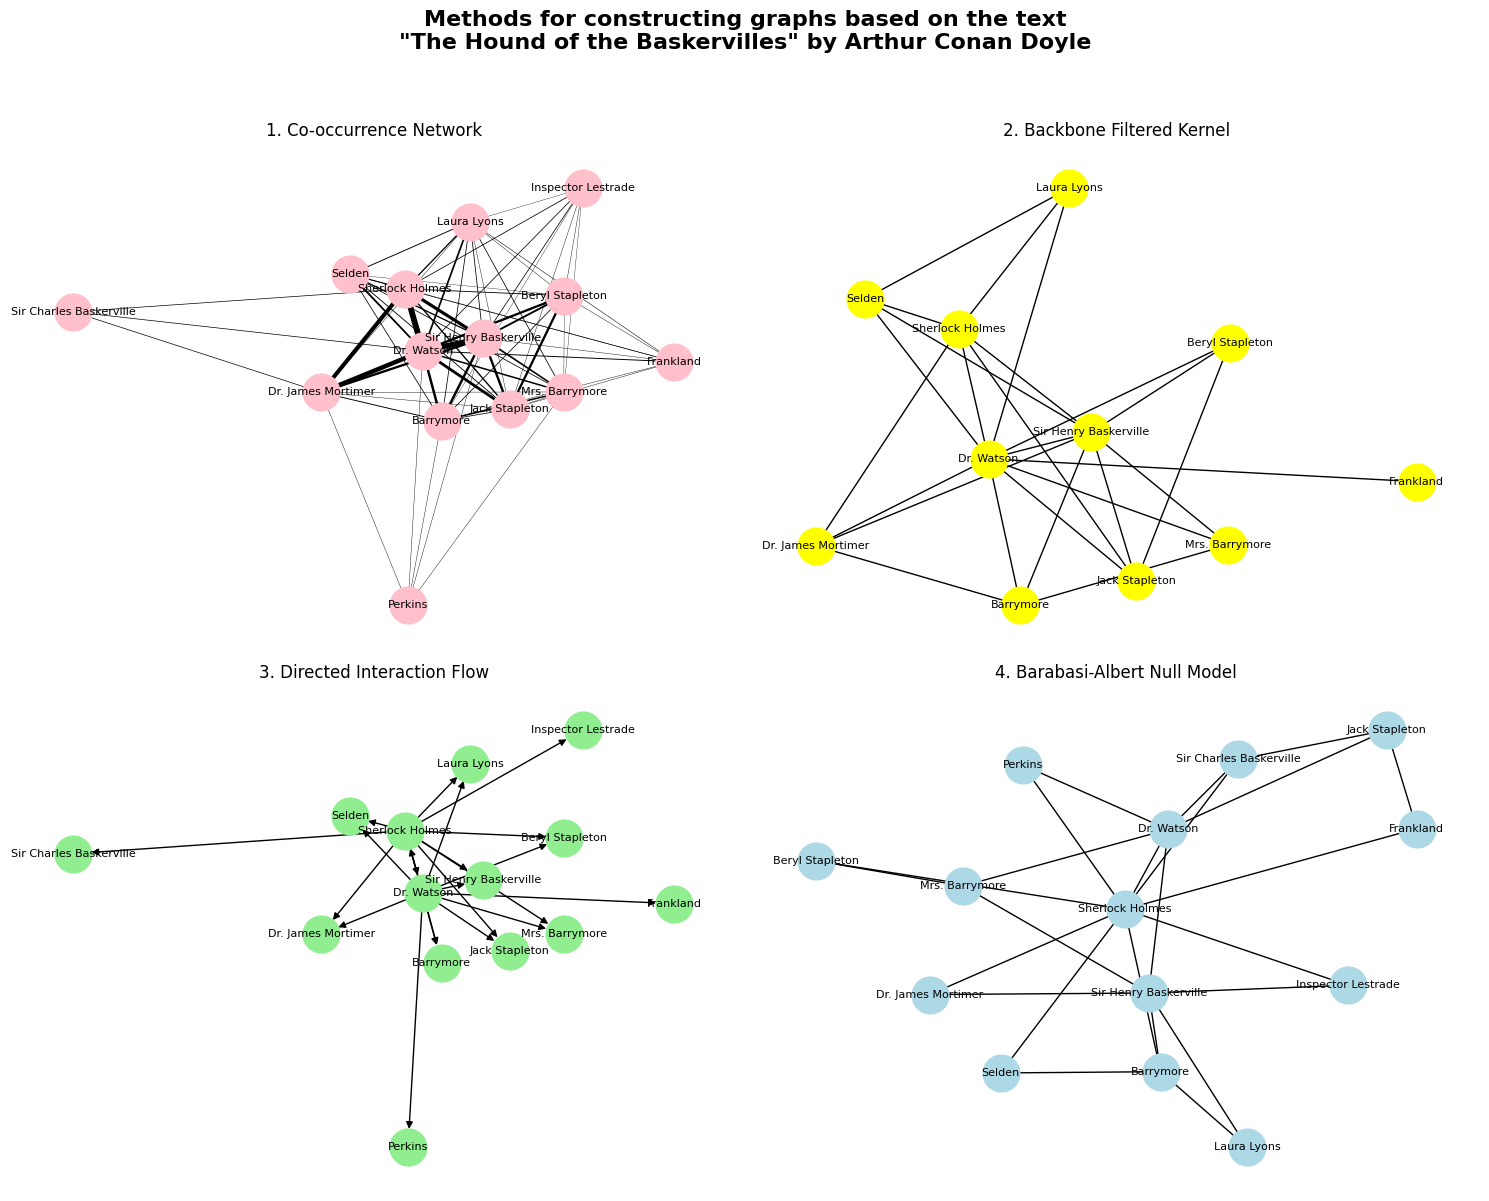

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 13))
pos = nx.spring_layout(G1, seed = 42)
fig.suptitle('Methods for constructing graphs based on the text\n"The Hound of the Baskervilles" by Arthur Conan Doyle',
             fontsize=16, fontweight="bold", y=0.95)

plt.sca(axes[0, 0])
axes[0, 0].set_title('1. Co-occurrence Network')
nx.draw(G1, pos, with_labels=True, node_color='pink', node_size=700, font_size=8,
        width=[d['newman_weight'] * 1.5 for i, j, d in G1.edges(data=True)])

plt.sca(axes[0, 1])
axes[0, 1].set_title('2. Backbone Filtered Kernel')
nx.draw(G2, pos, with_labels=True, node_color='yellow', node_size = 700, font_size = 8)

plt.sca(axes[1, 0])
axes[1, 0].set_title('3. Directed Interaction Flow')
nx.draw(G3, pos, with_labels=True, node_color='lightgreen', node_size=700, font_size=8, arrows=True)

plt.sca(axes[1, 1])
axes[1, 1].set_title('4. Barabasi-Albert Null Model')
nx.draw(G4, with_labels=True, node_color='lightblue', node_size=700, font_size=8)

plt.tight_layout(rect=[0, 0.03, 1, 0.92])
plt.show()

In [33]:
def get_metrics_summary(G, name):
    undir_G = G.to_undirected() if isinstance(G, nx.DiGraph) else G
    k_vals = [d for _, d in undir_G.degree()]
    return {
        "model": name,
        "V": undir_G.number_of_nodes(),
        "E": undir_G.number_of_edges(),
        "avg degree (k)": round(np.mean(k_vals), 2),
        "coeff of clastering (C)": round(nx.average_clustering(undir_G), 3),
        "assortativity (r)": round(nx.degree_assortativity_coefficient(undir_G), 3)
    }

summary_df = pd.DataFrame([
    get_metrics_summary(G1, "Co-occurrence (Newman Weighted)"),
    get_metrics_summary(G2, "Backbone Filtered Kernel"),
    get_metrics_summary(G3, "Directed Interaction Flow"),
    get_metrics_summary(G4, "Barabasi-Albert Null Model")
])

print("Comparison of network models")
print(summary_df.to_string(index=False))

Comparison of network models
                          model  V  E  avg degree (k)  coeff of clastering (C)  assortativity (r)
Co-occurrence (Newman Weighted) 14 68            9.71                    0.880             -0.263
       Backbone Filtered Kernel 11 25            4.55                    0.703             -0.480
      Directed Interaction Flow 14 21            3.00                    0.592             -0.906
     Barabasi-Albert Null Model 14 24            3.43                    0.368             -0.509
